# Project 2: Prediction of Material Removal Rate (MRR)
## Multiple Regression and Multilayer Perceptron

This project develops regression models for predicting Material Removal Rate (MRR)
in a Chemical Mechanical Polishing (CMP) process using the Data1 dataset.

The models considered are:

1. Multiple Linear Regression using self-coded Gradient Descent
2. Multiple Linear Regression using Scikit-learn
3. Three-layer MLP using self-coded forward and backpropagation
4. Three-layer MLP using PyTorch
5. Four-layer MLP using self-coded forward and backpropagation

Model performance will be evaluated using the coefficient of determination (R²)
and Root Mean Square Error (RMSE).

In [1]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

# Load the CMP dataset
mat_data = sio.loadmat('CMP_Data.mat')

# Display variables stored in the MATLAB file
print("Variables in CMP_Data.mat:")
print(mat_data.keys())

# Extract Data1
data = mat_data['Data1']

# Display dataset dimensions
print("\nData1 shape:", data.shape)

Variables in CMP_Data.mat:
dict_keys(['__header__', '__version__', '__globals__', 'Data1', 'Data2'])

Data1 shape: (364, 26)


## 1. Data Preparation

The Data1 dataset contains 26 variables. Columns 7–25 are the sensing/process
variables and column 26 is the Material Removal Rate (MRR), which is the prediction target.

The first six columns contain machine, wafer, and process-context information and
are not used as sensing predictors in this project.

In [2]:
#column names
column_names = [
    'MACHINE_ID',
    'MACHINE_DATA',
    'TIMESTAMP',
    'WAFER_ID',
    'STAGE',
    'CHAMBER',
    'USAGE_OF_BACKING_FILM',
    'USAGE_OF_DRESSER',
    'USAGE_OF_POLISHING_TABLE',
    'USAGE_OF_DRESSER_TABLE',
    'PRESSURIZED_CHAMBER_PRESSURE',
    'MAIN_OUTER_AIR_BAG_PRESSURE',
    'CENTER_AIR_BAG_PRESSURE',
    'RETAINER_RING_PRESSURE',
    'RIPPLE_AIR_BAG_PRESSURE',
    'USAGE_OF_MEMBRANE',
    'USAGE_OF_PRESSURIZED_SHEET',
    'SLURRY_FLOW_LINE_A',
    'SLURRY_FLOW_LINE_B',
    'SLURRY_FLOW_LINE_C',
    'WAFER_ROTATION',
    'STAGE_ROTATION',
    'HEAD_ROTATION',
    'DRESSING_WATER_STATUS',
    'EDGE_AIR_BAG_PRESSURE',
    'MRR'
]

# Select sensing/process variables x7-x25
X = data[:, 6:25]

# Select MRR target x26
y = data[:, 25]

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)
print("Number of sensing variables:", X.shape[1])

Input feature shape: (364, 19)
Target shape: (364,)
Number of sensing variables: 19


## 2. Outlier Treatment

To maintain consistency with Project 1, extreme values in the sensing variables
and MRR are treated using winsorization.

Values below μ − 3σ are clipped to μ − 3σ, while values above μ + 3σ
are clipped to μ + 3σ. This approach retains all samples while reducing
the influence of extreme observations.

In [3]:
cleaned_data = data.copy()

# Winsorize sensing variables x7-x25 and MRR x26
for i in range(6, 26):
    column = data[:, i]

    mean_value = np.mean(column)
    std_value = np.std(column)

    lower_limit = mean_value - 3 * std_value
    upper_limit = mean_value + 3 * std_value

    cleaned_data[:, i] = np.clip(
        column,
        lower_limit,
        upper_limit
    )

# Extract cleaned sensing variables and MRR
X_clean = cleaned_data[:, 6:25]
y_clean = cleaned_data[:, 25]

print("Cleaned input shape:", X_clean.shape)
print("Cleaned target shape:", y_clean.shape)

# Count values were clipped
total_clipped = np.sum(data[:, 6:26] != cleaned_data[:, 6:26])

print("Total values clipped:", total_clipped)

Cleaned input shape: (364, 19)
Cleaned target shape: (364,)
Total values clipped: 29


## 3. Input Variable Combinations

Two combinations of sensing variables are evaluated.

### Combination 1: All sensing variables
All 19 process variables from x7 to x25 are used.

### Combination 2: Pad and dresser condition variables
Only x7 to x10 are used:

- x7: USAGE_OF_BACKING_FILM
- x8: USAGE_OF_DRESSER
- x9: USAGE_OF_POLISHING_TABLE
- x10: USAGE_OF_DRESSER_TABLE

These variables are evaluated separately because their conditions change with use
and were specifically identified as important variables affecting MRR.

In [4]:
# Combination 1: All sensing variables x7-x25
X_all = X_clean.copy()

# Combination 2: Pad and dresser related variables x7-x10
X_pad_dresser = X_clean[:, 0:4]

print("Combination 1 - All sensing variables:", X_all.shape)
print("Combination 2 - x7 to x10:", X_pad_dresser.shape)

Combination 1 - All sensing variables: (364, 19)
Combination 2 - x7 to x10: (364, 4)


## 4. Training/Test Split and Normalization

The dataset is divided into training and testing sets using an 80/20 split.

To prevent data leakage, the normalization parameters are determined using only
the training data. The same transformation is then applied to the corresponding
test data.

Min-Max normalization is used to scale each sensing variable to the range [0, 1].

The same train/test sample indices are used for both input-variable combinations
to ensure a fair comparison between models.

In [5]:
from sklearn.model_selection import train_test_split

indices = np.arange(len(y_clean))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42
)


# Combination 1: All sensing variables x7-x25

X_all_train = X_all[train_idx]
X_all_test = X_all[test_idx]


# Combination 2: Pad and dresser variables x7-x10

X_pad_train = X_pad_dresser[train_idx]
X_pad_test = X_pad_dresser[test_idx]

# MRR target
y_train = y_clean[train_idx]
y_test = y_clean[test_idx]

print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))

print("\nCombination 1:")
print("X_all_train:", X_all_train.shape)
print("X_all_test :", X_all_test.shape)

print("\nCombination 2:")
print("X_pad_train:", X_pad_train.shape)
print("X_pad_test :", X_pad_test.shape)

print("\nMRR:")
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

Training samples: 291
Testing samples: 73

Combination 1:
X_all_train: (291, 19)
X_all_test : (73, 19)

Combination 2:
X_pad_train: (291, 4)
X_pad_test : (73, 4)

MRR:
y_train: (291,)
y_test : (73,)


In [6]:
from sklearn.preprocessing import MinMaxScaler


# Combination 1: All sensing variables

scaler_all = MinMaxScaler()

X_all_train_scaled = scaler_all.fit_transform(X_all_train)
X_all_test_scaled = scaler_all.transform(X_all_test)


# Combination 2: x7-x10

scaler_pad = MinMaxScaler()

X_pad_train_scaled = scaler_pad.fit_transform(X_pad_train)
X_pad_test_scaled = scaler_pad.transform(X_pad_test)

# Display training-data ranges after normalization
print("Combination 1 training range:")
print("Minimum:", X_all_train_scaled.min())
print("Maximum:", X_all_train_scaled.max())

print("\nCombination 2 training range:")
print("Minimum:", X_pad_train_scaled.min())
print("Maximum:", X_pad_train_scaled.max())

Combination 1 training range:
Minimum: 0.0
Maximum: 1.0000000000000002

Combination 2 training range:
Minimum: 0.0
Maximum: 1.0


## 5. Multiple Linear Regression Using Gradient Descent

A multiple linear regression model is first implemented from scratch using
gradient descent.

The prediction model is

$$
\hat{y} = Xw + b
$$

where \(w\) represents the regression coefficients and \(b\) is the intercept.

The model parameters are updated iteratively to minimize the Mean Squared Error
(MSE).

Two different feature combinations and multiple learning rates are evaluated.

## 5. Multiple Linear Regression Using Gradient Descent

A multiple linear regression model is implemented from scratch using **gradient descent** to predict Material Removal Rate (MRR).

For \(m\) input variables, the regression model is written as:

$$
\hat{y} = w_1x_1 + w_2x_2 + \cdots + w_mx_m + b
$$

or, in matrix form,

$$
\hat{y} = Xw + b
$$

where:

- \(X\) represents the input sensing variables,
- \(w\) represents the regression coefficients,
- \(b\) represents the intercept or bias,
- \(\hat{y}\) represents the predicted Material Removal Rate.

The model parameters are determined by minimizing the **Mean Squared Error (MSE)**:

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

The regression coefficients and bias are updated iteratively using gradient descent:

$$
w := w - \alpha \frac{\partial MSE}{\partial w}
$$

$$
b := b - \alpha \frac{\partial MSE}{\partial b}
$$

where **α** is the learning rate.

Two combinations of sensing variables are evaluated:

1. **Combination 1:** All sensing variables, **x7 through x25**
2. **Combination 2:** Pad and dresser condition variables, **x7 through x10**

Different learning rates are also tested to study their effect on convergence and prediction performance.

In [7]:
# Multiple Linear Regression using Gradient Descent

def linear_regression_gradient_descent(
    X,
    y,
    learning_rate=0.01,
    iterations=5000
):

    # Number of samples and features
    n_samples, n_features = X.shape

    # Initialize weights and bias
    weights = np.zeros(n_features)
    bias = 0.0

    # Store loss values
    loss_history = []

    # Gradient descent
    for i in range(iterations):

        # Prediction
        y_pred = np.dot(X, weights) + bias

        # Prediction error
        error = y_pred - y

        # Mean squared error
        mse = np.mean(error ** 2)
        loss_history.append(mse)

        # Gradients
        dw = (2 / n_samples) * np.dot(X.T, error)
        db = (2 / n_samples) * np.sum(error)

        # Update parameters
        weights = weights - learning_rate * dw
        bias = bias - learning_rate * db

    return weights, bias, loss_history

In [8]:
from sklearn.metrics import mean_squared_error, r2_score

# Prediction function
def predict_linear_regression(X, weights, bias):
    return np.dot(X, weights) + bias


# Evaluation function
def evaluate_regression(y_true, y_pred):

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return rmse, r2

In [9]:
# Trial 1
# Combination 1: All sensing variables
# Learning rate = 0.01


weights_all_lr1, bias_all_lr1, loss_all_lr1 = \
    linear_regression_gradient_descent(
        X_all_train_scaled,
        y_train,
        learning_rate=0.01,
        iterations=5000
    )

# Predict training and testing data
y_train_pred_all_lr1 = predict_linear_regression(
    X_all_train_scaled,
    weights_all_lr1,
    bias_all_lr1
)

y_test_pred_all_lr1 = predict_linear_regression(
    X_all_test_scaled,
    weights_all_lr1,
    bias_all_lr1
)

# Evaluate model
train_rmse_all_lr1, train_r2_all_lr1 = evaluate_regression(
    y_train,
    y_train_pred_all_lr1
)

test_rmse_all_lr1, test_r2_all_lr1 = evaluate_regression(
    y_test,
    y_test_pred_all_lr1
)

print("Combination 1: All sensing variables")
print("Learning rate: 0.01")

print("\nTraining performance")
print("RMSE:", train_rmse_all_lr1)
print("R2:", train_r2_all_lr1)

print("\nTesting performance")
print("RMSE:", test_rmse_all_lr1)
print("R2:", test_r2_all_lr1)

print("\nInitial loss:", loss_all_lr1[0])
print("Final loss:", loss_all_lr1[-1])

Combination 1: All sensing variables
Learning rate: 0.01

Training performance
RMSE: 4.608923765602514
R2: -0.39439921374827525

Testing performance
RMSE: 3.4702183746275144
R2: 0.16669791643833454

Initial loss: 22912.909717905186
Final loss: 21.243469173673347


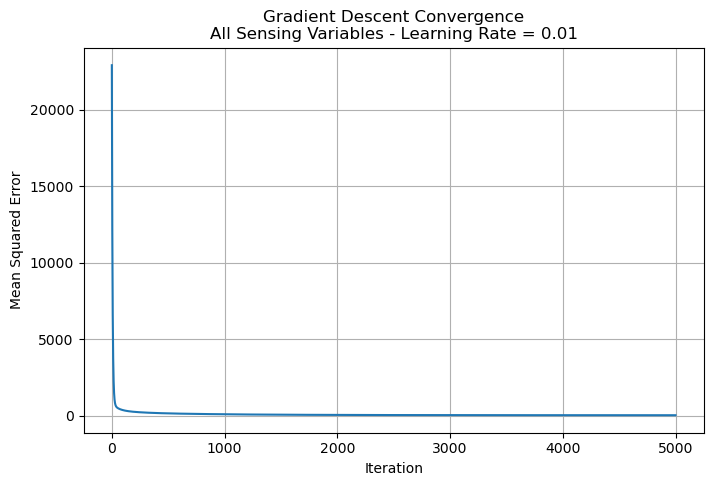

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(loss_all_lr1)

plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.title(
    "Gradient Descent Convergence\n"
    "All Sensing Variables - Learning Rate = 0.01"
)

plt.grid(True)

plt.show()

In [11]:
# Trial 2
# Combination 1: All sensing variables
# Learning rate = 0.001

weights_all_lr2, bias_all_lr2, loss_all_lr2 = \
    linear_regression_gradient_descent(
        X_all_train_scaled,
        y_train,
        learning_rate=0.001,
        iterations=10000
    )

# Predict training and testing data
y_train_pred_all_lr2 = predict_linear_regression(
    X_all_train_scaled,
    weights_all_lr2,
    bias_all_lr2
)

y_test_pred_all_lr2 = predict_linear_regression(
    X_all_test_scaled,
    weights_all_lr2,
    bias_all_lr2
)

# Evaluate model
train_rmse_all_lr2, train_r2_all_lr2 = evaluate_regression(
    y_train,
    y_train_pred_all_lr2
)

test_rmse_all_lr2, test_r2_all_lr2 = evaluate_regression(
    y_test,
    y_test_pred_all_lr2
)

print("Combination 1: All sensing variables")
print("Learning rate: 0.001")

print("\nTraining performance")
print("RMSE:", train_rmse_all_lr2)
print("R2:", train_r2_all_lr2)

print("\nTesting performance")
print("RMSE:", test_rmse_all_lr2)
print("R2:", test_r2_all_lr2)

print("\nInitial loss:", loss_all_lr2[0])
print("Final loss:", loss_all_lr2[-1])

Combination 1: All sensing variables
Learning rate: 0.001

Training performance
RMSE: 9.13543654216688
R2: -4.478311088531252

Testing performance
RMSE: 8.62751460704477
R2: -4.150628945802761

Initial loss: 22912.909717905186
Final loss: 83.46384274783317


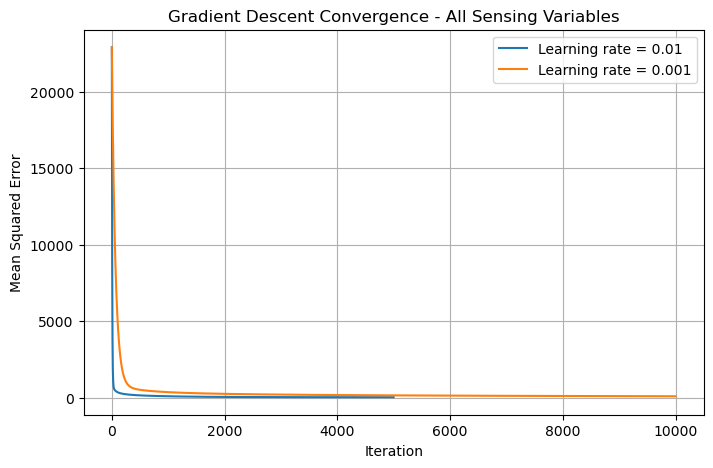

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(loss_all_lr1, label="Learning rate = 0.01")
plt.plot(loss_all_lr2, label="Learning rate = 0.001")

plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent Convergence - All Sensing Variables")

plt.legend()
plt.grid(True)

plt.savefig(
    "gd_convergence_all_variables.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [13]:
# Gradient Descent Learning-Rate Comparison
# Combination 1: All sensing variables


# Learning rate 1
weights_all_lr1, bias_all_lr1, loss_all_lr1 = \
    linear_regression_gradient_descent(
        X_all_train_scaled,
        y_train,
        learning_rate=0.01,
        iterations=50000
    )

# Learning rate 2
weights_all_lr2, bias_all_lr2, loss_all_lr2 = \
    linear_regression_gradient_descent(
        X_all_train_scaled,
        y_train,
        learning_rate=0.001,
        iterations=100000
    )


# Predictions - learning rate 0.01


y_train_pred_all_lr1 = predict_linear_regression(
    X_all_train_scaled,
    weights_all_lr1,
    bias_all_lr1
)

y_test_pred_all_lr1 = predict_linear_regression(
    X_all_test_scaled,
    weights_all_lr1,
    bias_all_lr1
)

train_rmse_all_lr1, train_r2_all_lr1 = evaluate_regression(
    y_train,
    y_train_pred_all_lr1
)

test_rmse_all_lr1, test_r2_all_lr1 = evaluate_regression(
    y_test,
    y_test_pred_all_lr1
)


# Predictions - learning rate 0.001


y_train_pred_all_lr2 = predict_linear_regression(
    X_all_train_scaled,
    weights_all_lr2,
    bias_all_lr2
)

y_test_pred_all_lr2 = predict_linear_regression(
    X_all_test_scaled,
    weights_all_lr2,
    bias_all_lr2
)

train_rmse_all_lr2, train_r2_all_lr2 = evaluate_regression(
    y_train,
    y_train_pred_all_lr2
)

test_rmse_all_lr2, test_r2_all_lr2 = evaluate_regression(
    y_test,
    y_test_pred_all_lr2
)


# Display results


print("COMBINATION 1: ALL SENSING VARIABLES")

print("\nLearning rate = 0.01")
print("Train RMSE:", train_rmse_all_lr1)
print("Train R2:", train_r2_all_lr1)
print("Test RMSE:", test_rmse_all_lr1)
print("Test R2:", test_r2_all_lr1)
print("Final loss:", loss_all_lr1[-1])

print("\nLearning rate = 0.001")
print("Train RMSE:", train_rmse_all_lr2)
print("Train R2:", train_r2_all_lr2)
print("Test RMSE:", test_rmse_all_lr2)
print("Test R2:", test_r2_all_lr2)
print("Final loss:", loss_all_lr2[-1])

COMBINATION 1: ALL SENSING VARIABLES

Learning rate = 0.01
Train RMSE: 3.2668240216378504
Train R2: 0.2994493173393068
Test RMSE: 3.234949445894965
Test R2: 0.2758578052753705
Final loss: 10.672178273539375

Learning rate = 0.001
Train RMSE: 4.211903216139175
Train R2: -0.16451435400389758
Test RMSE: 3.2588507406052014
Test R2: 0.2651176834925988
Final loss: 17.74017909571388


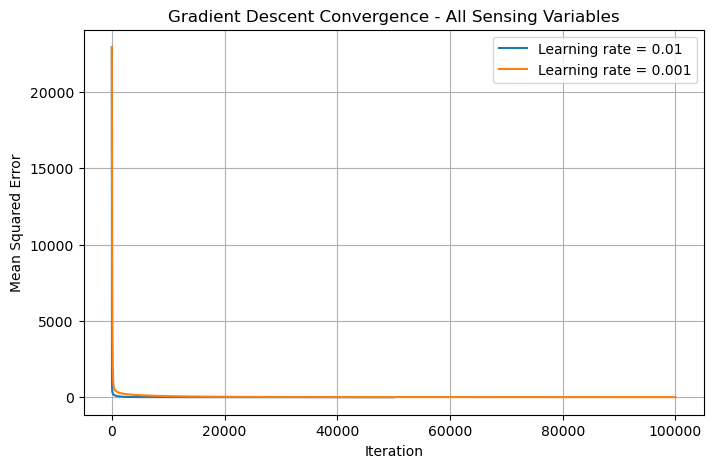

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(loss_all_lr1, label="Learning rate = 0.01")
plt.plot(loss_all_lr2, label="Learning rate = 0.001")

plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent Convergence - All Sensing Variables")

plt.legend()
plt.grid(True)

plt.show()

In [15]:
# Gradient Descent
# Combination 2: Pad and Dresser Variables x7-x10


# Learning rate = 0.01
weights_pad_lr1, bias_pad_lr1, loss_pad_lr1 = \
    linear_regression_gradient_descent(
        X_pad_train_scaled,
        y_train,
        learning_rate=0.01,
        iterations=50000
    )

# Learning rate = 0.001
weights_pad_lr2, bias_pad_lr2, loss_pad_lr2 = \
    linear_regression_gradient_descent(
        X_pad_train_scaled,
        y_train,
        learning_rate=0.001,
        iterations=100000
    )


# Predictions - learning rate 0.01


y_train_pred_pad_lr1 = predict_linear_regression(
    X_pad_train_scaled,
    weights_pad_lr1,
    bias_pad_lr1
)

y_test_pred_pad_lr1 = predict_linear_regression(
    X_pad_test_scaled,
    weights_pad_lr1,
    bias_pad_lr1
)

train_rmse_pad_lr1, train_r2_pad_lr1 = evaluate_regression(
    y_train,
    y_train_pred_pad_lr1
)

test_rmse_pad_lr1, test_r2_pad_lr1 = evaluate_regression(
    y_test,
    y_test_pred_pad_lr1
)



# Predictions - learning rate 0.001


y_train_pred_pad_lr2 = predict_linear_regression(
    X_pad_train_scaled,
    weights_pad_lr2,
    bias_pad_lr2
)

y_test_pred_pad_lr2 = predict_linear_regression(
    X_pad_test_scaled,
    weights_pad_lr2,
    bias_pad_lr2
)

train_rmse_pad_lr2, train_r2_pad_lr2 = evaluate_regression(
    y_train,
    y_train_pred_pad_lr2
)

test_rmse_pad_lr2, test_r2_pad_lr2 = evaluate_regression(
    y_test,
    y_test_pred_pad_lr2
)


# Display results


print("COMBINATION 2: PAD AND DRESSER VARIABLES x7-x10")

print("\nLearning rate = 0.01")
print("Train RMSE:", train_rmse_pad_lr1)
print("Train R2:", train_r2_pad_lr1)
print("Test RMSE:", test_rmse_pad_lr1)
print("Test R2:", test_r2_pad_lr1)
print("Final loss:", loss_pad_lr1[-1])

print("\nLearning rate = 0.001")
print("Train RMSE:", train_rmse_pad_lr2)
print("Train R2:", train_r2_pad_lr2)
print("Test RMSE:", test_rmse_pad_lr2)
print("Test R2:", test_r2_pad_lr2)
print("Final loss:", loss_pad_lr2[-1])

COMBINATION 2: PAD AND DRESSER VARIABLES x7-x10

Learning rate = 0.01
Train RMSE: 3.3632106741674543
Train R2: 0.2575003978717557
Test RMSE: 3.2626518039797126
Test R2: 0.26340237737575445
Final loss: 11.311186038833903

Learning rate = 0.001
Train RMSE: 3.3637193734100967
Train R2: 0.2572757687379499
Test RMSE: 3.2709076806426975
Test R2: 0.2596698594389456
Final loss: 11.314608407493514


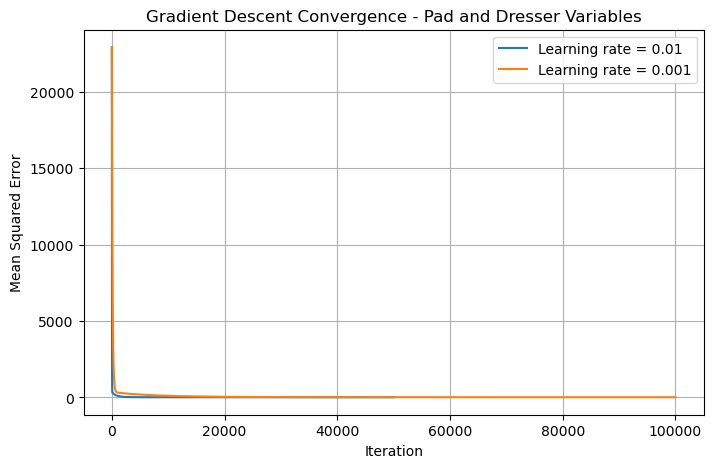

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(loss_pad_lr1, label="Learning rate = 0.01")
plt.plot(loss_pad_lr2, label="Learning rate = 0.001")

plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent Convergence - Pad and Dresser Variables")

plt.legend()
plt.grid(True)

plt.savefig(
    "gd_convergence_x7_x10.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [17]:
print("GRADIENT DESCENT PERFORMANCE SUMMARY")
print("=" * 72)

print("\nCombination 1: All sensing variables")
print("LR = 0.01  | Test RMSE:",
      round(test_rmse_all_lr1, 4),
      "| Test R2:",
      round(test_r2_all_lr1, 4))

print("LR = 0.001 | Test RMSE:",
      round(test_rmse_all_lr2, 4),
      "| Test R2:",
      round(test_r2_all_lr2, 4))

print("\nCombination 2: x7-x10")
print("LR = 0.01  | Test RMSE:",
      round(test_rmse_pad_lr1, 4),
      "| Test R2:",
      round(test_r2_pad_lr1, 4))

print("LR = 0.001 | Test RMSE:",
      round(test_rmse_pad_lr2, 4),
      "| Test R2:",
      round(test_r2_pad_lr2, 4))

GRADIENT DESCENT PERFORMANCE SUMMARY

Combination 1: All sensing variables
LR = 0.01  | Test RMSE: 3.2349 | Test R2: 0.2759
LR = 0.001 | Test RMSE: 3.2589 | Test R2: 0.2651

Combination 2: x7-x10
LR = 0.01  | Test RMSE: 3.2627 | Test R2: 0.2634
LR = 0.001 | Test RMSE: 3.2709 | Test R2: 0.2597


### Gradient Descent Results and Interpretation

The multiple linear regression model was evaluated using two combinations of input variables
and two learning rates.

For the model using all sensing variables (x7–x25), a learning rate of **0.01**
produced the best test performance, with an RMSE of approximately **3.2349**
and an R² value of approximately **0.2759**.

Using the smaller learning rate of **0.001** resulted in slightly poorer performance,
with a test RMSE of approximately **3.2589** and an R² value of approximately **0.2651**.
The smaller learning rate also required more iterations to approach convergence.

For the model using only the pad and dresser variables (x7–x10), the learning rate
of **0.01** again performed slightly better, producing a test RMSE of approximately
**3.2627** and an R² value of approximately **0.2634**.

Overall, the model using all 19 sensing variables achieved the best gradient-descent
performance. However, the x7–x10 model produced relatively similar results despite
using only four input variables. This suggests that the pad and dresser condition
variables contain important information related to MRR prediction.m

## 6. Multiple Linear Regression Using Scikit-Learn

The same two input-variable combinations are now evaluated using the
`LinearRegression` model from the Scikit-learn library.

This provides a comparison between the manually implemented gradient-descent
solution and a standard library implementation of multiple linear regression.

The models are evaluated using RMSE and R² on the same training and testing
datasets used in the gradient-descent experiments.

In [18]:
from sklearn.linear_model import LinearRegression

# Scikit-Learn Linear Regression

# Combination 1: All sensing variables


sk_model_all = LinearRegression()

sk_model_all.fit(
    X_all_train_scaled,
    y_train
)

y_train_pred_sk_all = sk_model_all.predict(
    X_all_train_scaled
)

y_test_pred_sk_all = sk_model_all.predict(
    X_all_test_scaled
)

train_rmse_sk_all, train_r2_sk_all = evaluate_regression(
    y_train,
    y_train_pred_sk_all
)

test_rmse_sk_all, test_r2_sk_all = evaluate_regression(
    y_test,
    y_test_pred_sk_all
)



# Combination 2: x7-x10


sk_model_pad = LinearRegression()

sk_model_pad.fit(
    X_pad_train_scaled,
    y_train
)

y_train_pred_sk_pad = sk_model_pad.predict(
    X_pad_train_scaled
)

y_test_pred_sk_pad = sk_model_pad.predict(
    X_pad_test_scaled
)

train_rmse_sk_pad, train_r2_sk_pad = evaluate_regression(
    y_train,
    y_train_pred_sk_pad
)

test_rmse_sk_pad, test_r2_sk_pad = evaluate_regression(
    y_test,
    y_test_pred_sk_pad
)



# Display results


print("SCIKIT-LEARN LINEAR REGRESSION")
print("=" * 60)

print("\nCombination 1: All sensing variables")
print("Train RMSE:", train_rmse_sk_all)
print("Train R2:", train_r2_sk_all)
print("Test RMSE:", test_rmse_sk_all)
print("Test R2:", test_r2_sk_all)

print("\nCombination 2: x7-x10")
print("Train RMSE:", train_rmse_sk_pad)
print("Train R2:", train_r2_sk_pad)
print("Test RMSE:", test_rmse_sk_pad)
print("Test R2:", test_r2_sk_pad)

SCIKIT-LEARN LINEAR REGRESSION

Combination 1: All sensing variables
Train RMSE: 3.14699653020195
Train R2: 0.349899338449964
Test RMSE: 3.3264742515919608
Test R2: 0.23430256899317625

Combination 2: x7-x10
Train RMSE: 3.3632106741674552
Train R2: 0.2575003978717554
Test RMSE: 3.2626518039783154
Test R2: 0.2634023773763853


In [19]:
# Gradient Descent with Practical Relative Convergence Check


def linear_regression_gd_converged(
    X,
    y,
    learning_rate=0.01,
    max_iterations=300000,
    check_interval=1000,
    tolerance=1e-6
):

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0

    loss_history = []
    previous_checked_loss = None

    for i in range(max_iterations):

        # Prediction
        y_pred = np.dot(X, weights) + bias

        # Error
        error = y_pred - y

        # MSE
        mse = np.mean(error ** 2)

        # Check convergence periodically
        if i % check_interval == 0:

            loss_history.append(mse)

            if previous_checked_loss is not None:

                relative_change = abs(
                    previous_checked_loss - mse
                ) / max(abs(previous_checked_loss), 1e-12)

                if relative_change < tolerance:
                    print(
                        f"Converged at iteration {i} "
                        f"with learning rate {learning_rate}"
                    )
                    break

            previous_checked_loss = mse

        # Gradients
        dw = (2 / n_samples) * np.dot(X.T, error)
        db = (2 / n_samples) * np.sum(error)

        # Update
        weights -= learning_rate * dw
        bias -= learning_rate * db

    else:
        print(
            f"Maximum iterations reached for "
            f"learning rate {learning_rate}"
        )

    return weights, bias, loss_history, i

In [20]:
# Final Gradient Descent Learning-Rate Trials
# Combination 1: All sensing variables


# Learning rate = 0.05
weights_all_lr005, bias_all_lr005, loss_all_lr005, iter_all_lr005 = \
    linear_regression_gd_converged(
        X_all_train_scaled,
        y_train,
        learning_rate=0.05,
        max_iterations=200000,
        check_interval=1000,
        tolerance=1e-6
    )

# Learning rate = 0.02
weights_all_lr002, bias_all_lr002, loss_all_lr002, iter_all_lr002 = \
    linear_regression_gd_converged(
        X_all_train_scaled,
        y_train,
        learning_rate=0.02,
        max_iterations=200000,
        check_interval=1000,
        tolerance=1e-6
    )

Converged at iteration 149000 with learning rate 0.05
Maximum iterations reached for learning rate 0.02


In [21]:
# Evaluate final learning-rate trials

# Learning rate = 0.05
y_train_pred_all_lr005 = predict_linear_regression(
    X_all_train_scaled,
    weights_all_lr005,
    bias_all_lr005
)

y_test_pred_all_lr005 = predict_linear_regression(
    X_all_test_scaled,
    weights_all_lr005,
    bias_all_lr005
)

train_rmse_all_lr005, train_r2_all_lr005 = evaluate_regression(
    y_train,
    y_train_pred_all_lr005
)

test_rmse_all_lr005, test_r2_all_lr005 = evaluate_regression(
    y_test,
    y_test_pred_all_lr005
)


# Learning rate = 0.02
y_train_pred_all_lr002 = predict_linear_regression(
    X_all_train_scaled,
    weights_all_lr002,
    bias_all_lr002
)

y_test_pred_all_lr002 = predict_linear_regression(
    X_all_test_scaled,
    weights_all_lr002,
    bias_all_lr002
)

train_rmse_all_lr002, train_r2_all_lr002 = evaluate_regression(
    y_train,
    y_train_pred_all_lr002
)

test_rmse_all_lr002, test_r2_all_lr002 = evaluate_regression(
    y_test,
    y_test_pred_all_lr002
)


print("ALL SENSING VARIABLES")

print("\nLearning rate = 0.05")
print("Iterations:", iter_all_lr005)
print("Train RMSE:", train_rmse_all_lr005)
print("Train R2:", train_r2_all_lr005)
print("Test RMSE:", test_rmse_all_lr005)
print("Test R2:", test_r2_all_lr005)

print("\nLearning rate = 0.02")
print("Iterations:", iter_all_lr002)
print("Train RMSE:", train_rmse_all_lr002)
print("Train R2:", train_r2_all_lr002)
print("Test RMSE:", test_rmse_all_lr002)
print("Test R2:", test_r2_all_lr002)

ALL SENSING VARIABLES

Learning rate = 0.05
Iterations: 149000
Train RMSE: 3.1583301544168445
Train R2: 0.3452083487290114
Test RMSE: 3.3313742223532854
Test R2: 0.2320451288012485

Learning rate = 0.02
Iterations: 199999
Train RMSE: 3.1586955873928035
Train R2: 0.34505681529641585
Test RMSE: 3.3265983868820213
Test R2: 0.23424542028916284


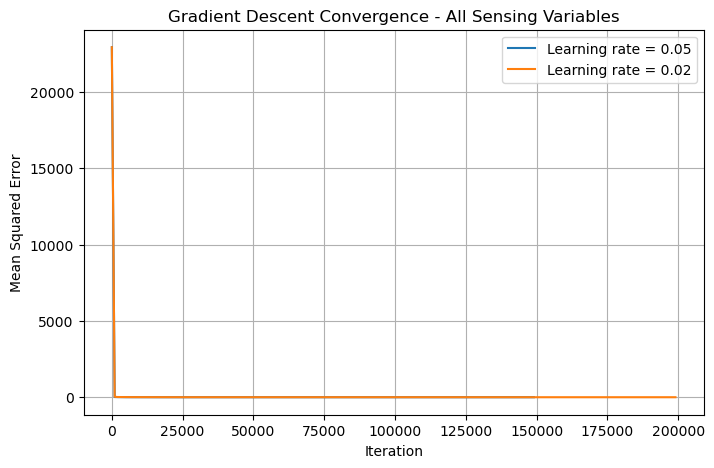

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    np.arange(len(loss_all_lr005)) * 1000,
    loss_all_lr005,
    label="Learning rate = 0.05"
)

plt.plot(
    np.arange(len(loss_all_lr002)) * 1000,
    loss_all_lr002,
    label="Learning rate = 0.02"
)

plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent Convergence - All Sensing Variables")

plt.legend()
plt.grid(True)

plt.show()

## 7. Three-Layer MLP Using Self-Coded Forward and Backpropagation

A three-layer Multilayer Perceptron (MLP) is implemented from scratch to predict
Material Removal Rate (MRR).

The network consists of:

1. An input layer containing the selected sensing variables
2. One hidden layer
3. One output layer for predicted MRR

The hidden layer uses the ReLU activation function, while the output layer uses
a linear activation because MRR prediction is a regression problem.

The network parameters are updated using manually implemented forward propagation
and backpropagation.

The following effects are investigated:

- Different input-variable combinations
- Different numbers of hidden-layer neurons
- Different learning rates

Model performance is evaluated using RMSE and R².

In [23]:

# Self-Coded Three-Layer MLP


class MLPRegressorScratch:

    def __init__(
        self,
        input_size,
        hidden_size,
        learning_rate=0.01,
        random_state=42
    ):

        np.random.seed(random_state)

        self.learning_rate = learning_rate

        # weights with small random values
        self.W1 = np.random.randn(
            input_size,
            hidden_size
        ) * np.sqrt(2.0 / input_size)

        self.b1 = np.zeros((1, hidden_size))

        self.W2 = np.random.randn(
            hidden_size,
            1
        ) * np.sqrt(2.0 / hidden_size)

        self.b2 = np.zeros((1, 1))

        self.loss_history = []


    # ReLU activation
    
    def relu(self, z):
        return np.maximum(0, z)


 
    # Derivative of ReLU

    def relu_derivative(self, z):
        return (z > 0).astype(float)



    # Forward propagation

    def forward(self, X):

        self.Z1 = np.dot(X, self.W1) + self.b1

        self.A1 = self.relu(self.Z1)

        self.Z2 = np.dot(self.A1, self.W2) + self.b2

        # Linear output for regression
        y_pred = self.Z2

        return y_pred


    # Backpropagation

    def backward(self, X, y, y_pred):

        n_samples = X.shape[0]

        # Make y a column vector
        y = y.reshape(-1, 1)

        # Output-layer gradient
        dZ2 = (2 / n_samples) * (y_pred - y)

        dW2 = np.dot(self.A1.T, dZ2)
        db2 = np.sum(dZ2, axis=0, keepdims=True)

        # Hidden-layer gradient
        dA1 = np.dot(dZ2, self.W2.T)

        dZ1 = dA1 * self.relu_derivative(self.Z1)

        dW1 = np.dot(X.T, dZ1)
        db1 = np.sum(dZ1, axis=0, keepdims=True)

        # Update weights and biases
        self.W2 -= self.learning_rate * dW2
        self.b2 -= self.learning_rate * db2

        self.W1 -= self.learning_rate * dW1
        self.b1 -= self.learning_rate * db1


    # Training

    def fit(self, X, y, epochs=10000):

        self.loss_history = []

        y_column = y.reshape(-1, 1)

        for epoch in range(epochs):

            # Forward propagation
            y_pred = self.forward(X)

            # Mean Squared Error
            loss = np.mean((y_pred - y_column) ** 2)

            self.loss_history.append(loss)

            # Backpropagation
            self.backward(
                X,
                y,
                y_pred
            )

        return self



    # Prediction

    def predict(self, X):

        return self.forward(X).flatten()

### 7.1 Initial Three-Layer MLP Trial

The first experiment uses all 19 sensing variables with one hidden layer
containing 8 neurons.

A learning rate of 0.001 is used initially to verify that the manually
implemented forward and backpropagation algorithm trains correctly.

The network architecture is:

**19 inputs → 8 hidden neurons → 1 MRR output**

In [24]:
# Self-Coded 3-Layer MLP - Trial 1
# All sensing variables
# Hidden neurons = 8
# Learning rate = 0.001


mlp_trial1 = MLPRegressorScratch(
    input_size=X_all_train_scaled.shape[1],
    hidden_size=8,
    learning_rate=0.001,
    random_state=42
)

mlp_trial1.fit(
    X_all_train_scaled,
    y_train,
    epochs=10000
)

# Predictions
y_train_pred_mlp1 = mlp_trial1.predict(
    X_all_train_scaled
)

y_test_pred_mlp1 = mlp_trial1.predict(
    X_all_test_scaled
)

# Evaluation
train_rmse_mlp1, train_r2_mlp1 = evaluate_regression(
    y_train,
    y_train_pred_mlp1
)

test_rmse_mlp1, test_r2_mlp1 = evaluate_regression(
    y_test,
    y_test_pred_mlp1
)

print("SELF-CODED 3-LAYER MLP - TRIAL 1")
print("=" * 55)

print("Input variables: All sensing variables x7-x25")
print("Hidden neurons: 8")
print("Learning rate: 0.001")
print("Epochs: 10000")

print("\nTraining Performance")
print("RMSE:", train_rmse_mlp1)
print("R2:", train_r2_mlp1)

print("\nTesting Performance")
print("RMSE:", test_rmse_mlp1)
print("R2:", test_r2_mlp1)

print("\nInitial loss:", mlp_trial1.loss_history[0])
print("Final loss:", mlp_trial1.loss_history[-1])

SELF-CODED 3-LAYER MLP - TRIAL 1
Input variables: All sensing variables x7-x25
Hidden neurons: 8
Learning rate: 0.001
Epochs: 10000

Training Performance
RMSE: 3.110937710975585
R2: 0.3647119139302768

Testing Performance
RMSE: 3.2652882204004814
R2: 0.26221146715835353

Initial loss: 22873.304417116957
Final loss: 9.677997191241781


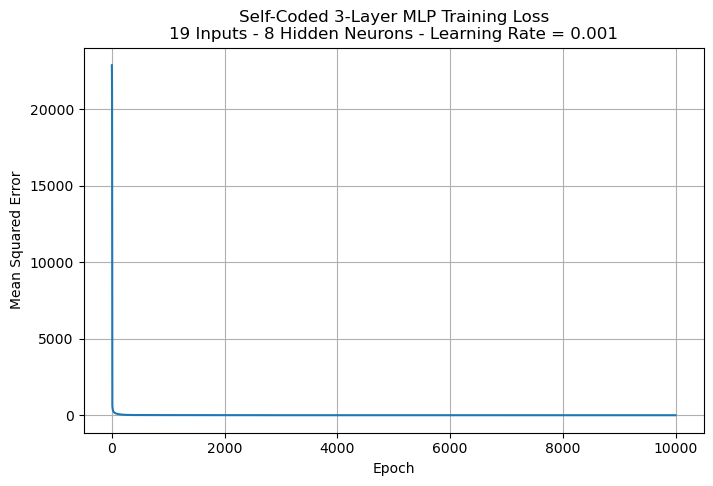

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(mlp_trial1.loss_history)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title(
    "Self-Coded 3-Layer MLP Training Loss\n"
    "19 Inputs - 8 Hidden Neurons - Learning Rate = 0.001"
)

plt.grid(True)
plt.savefig(
    "self_coded_3layer_mlp_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
# Hidden-Neuron Comparison
# Self-Coded 3-Layer MLP
# All sensing variables
# Learning rate = 0.001


hidden_sizes = [8, 16, 32]

mlp_hidden_results = []

for hidden_size in hidden_sizes:

    model = MLPRegressorScratch(
        input_size=X_all_train_scaled.shape[1],
        hidden_size=hidden_size,
        learning_rate=0.001,
        random_state=42
    )

    model.fit(
        X_all_train_scaled,
        y_train,
        epochs=10000
    )

    # Predictions
    y_train_pred = model.predict(
        X_all_train_scaled
    )

    y_test_pred = model.predict(
        X_all_test_scaled
    )

    # Evaluation
    train_rmse, train_r2 = evaluate_regression(
        y_train,
        y_train_pred
    )

    test_rmse, test_r2 = evaluate_regression(
        y_test,
        y_test_pred
    )

    mlp_hidden_results.append({
        "hidden_neurons": hidden_size,
        "train_rmse": train_rmse,
        "train_r2": train_r2,
        "test_rmse": test_rmse,
        "test_r2": test_r2,
        "final_loss": model.loss_history[-1]
    })

    print(
        f"Hidden neurons = {hidden_size}"
    )
    print(
        "Train RMSE:",
        train_rmse
    )
    print(
        "Train R2:",
        train_r2
    )
    print(
        "Test RMSE:",
        test_rmse
    )
    print(
        "Test R2:",
        test_r2
    )
    print(
        "Final loss:",
        model.loss_history[-1]
    )
    print("-" * 50)

Hidden neurons = 8
Train RMSE: 3.110937710975585
Train R2: 0.3647119139302768
Test RMSE: 3.2652882204004814
Test R2: 0.26221146715835353
Final loss: 9.677997191241781
--------------------------------------------------
Hidden neurons = 16
Train RMSE: 3.0703682604164904
Train R2: 0.3811733396756284
Test RMSE: 3.318559889556628
Test R2: 0.2379417360051962
Final loss: 9.427276925652434
--------------------------------------------------
Hidden neurons = 32
Train RMSE: 2.9439504314451796
Train R2: 0.43108279665387195
Test RMSE: 3.2937020632089316
Test R2: 0.24931544357293633
Final loss: 8.667017539488986
--------------------------------------------------


In [27]:
print("SELF-CODED 3-LAYER MLP - HIDDEN NEURON COMPARISON")
print("=" * 75)

print(
    f"{'Hidden':<10}"
    f"{'Train RMSE':<15}"
    f"{'Train R2':<15}"
    f"{'Test RMSE':<15}"
    f"{'Test R2':<15}"
)

for result in mlp_hidden_results:

    print(
        f"{result['hidden_neurons']:<10}"
        f"{result['train_rmse']:<15.4f}"
        f"{result['train_r2']:<15.4f}"
        f"{result['test_rmse']:<15.4f}"
        f"{result['test_r2']:<15.4f}"
    )

SELF-CODED 3-LAYER MLP - HIDDEN NEURON COMPARISON
Hidden    Train RMSE     Train R2       Test RMSE      Test R2        
8         3.1109         0.3647         3.2653         0.2622         
16        3.0704         0.3812         3.3186         0.2379         
32        2.9440         0.4311         3.2937         0.2493         


### Hidden-Neuron Comparison

Three hidden-layer sizes were evaluated: 8, 16, and 32 neurons.

Increasing the number of hidden neurons improved the training performance.
The 32-neuron model achieved the lowest training RMSE and highest training R².

However, the best testing performance was obtained using **8 hidden neurons**,
with a test RMSE of approximately **3.2653** and a test R² of approximately
**0.2622**.

The larger hidden layers improved the fit to the training data but did not improve
generalization to the test data. Therefore, 8 hidden neurons were selected for
the subsequent learning-rate experiments.

In [28]:
# Learning-Rate Comparison
# Self-Coded 3-Layer MLP
# All sensing variables
# Hidden neurons = 8

learning_rates = [0.0005, 0.001, 0.005]

mlp_lr_results = []

for lr in learning_rates:

    model = MLPRegressorScratch(
        input_size=X_all_train_scaled.shape[1],
        hidden_size=8,
        learning_rate=lr,
        random_state=42
    )

    model.fit(
        X_all_train_scaled,
        y_train,
        epochs=10000
    )

    # Predictions
    y_train_pred = model.predict(
        X_all_train_scaled
    )

    y_test_pred = model.predict(
        X_all_test_scaled
    )

    # Evaluation
    train_rmse, train_r2 = evaluate_regression(
        y_train,
        y_train_pred
    )

    test_rmse, test_r2 = evaluate_regression(
        y_test,
        y_test_pred
    )

    mlp_lr_results.append({
        "learning_rate": lr,
        "train_rmse": train_rmse,
        "train_r2": train_r2,
        "test_rmse": test_rmse,
        "test_r2": test_r2,
        "final_loss": model.loss_history[-1]
    })

    print("Learning rate =", lr)
    print("Train RMSE:", train_rmse)
    print("Train R2:", train_r2)
    print("Test RMSE:", test_rmse)
    print("Test R2:", test_r2)
    print("Final loss:", model.loss_history[-1])
    print("-" * 50)

Learning rate = 0.0005
Train RMSE: 3.157064602206485
Train R2: 0.3457329974865646
Test RMSE: 3.2383463215281205
Test R2: 0.2743362282051125
Final loss: 9.967180628530338
--------------------------------------------------
Learning rate = 0.001
Train RMSE: 3.110937710975585
Train R2: 0.3647119139302768
Test RMSE: 3.2652882204004814
Test R2: 0.26221146715835353
Final loss: 9.677997191241781
--------------------------------------------------
Learning rate = 0.005
Train RMSE: 3.9030665833658342
Train R2: 0.0
Test RMSE: 3.8197395941425283
Test R2: -0.00961633962047137
Final loss: 15.233928754187046
--------------------------------------------------


In [29]:
print("SELF-CODED 3-LAYER MLP - LEARNING RATE COMPARISON")
print("=" * 75)

print(
    f"{'Learning Rate':<18}"
    f"{'Train RMSE':<15}"
    f"{'Train R2':<15}"
    f"{'Test RMSE':<15}"
    f"{'Test R2':<15}"
)

for result in mlp_lr_results:

    print(
        f"{result['learning_rate']:<18}"
        f"{result['train_rmse']:<15.4f}"
        f"{result['train_r2']:<15.4f}"
        f"{result['test_rmse']:<15.4f}"
        f"{result['test_r2']:<15.4f}"
    )

SELF-CODED 3-LAYER MLP - LEARNING RATE COMPARISON
Learning Rate     Train RMSE     Train R2       Test RMSE      Test R2        
0.0005            3.1571         0.3457         3.2383         0.2743         
0.001             3.1109         0.3647         3.2653         0.2622         
0.005             3.9031         0.0000         3.8197         -0.0096        


### Learning-Rate Comparison

Three learning rates were evaluated using 8 hidden neurons and all 19 sensing variables.

The learning rate of **0.0005** produced the best testing performance, with a
test RMSE of approximately **3.2383** and a test R² of approximately **0.2743**.

The learning rate of **0.001** achieved slightly better training performance,
but its test performance was lower, with a test RMSE of approximately **3.2653**
and a test R² of approximately **0.2622**.

The larger learning rate of **0.005** resulted in poor performance, with an R²
close to zero on the training data and a negative test R². This indicates that
the learning rate was too large for stable optimization of this network.

Therefore, a learning rate of **0.0005** was selected for the input-variable
comparison.

In [30]:
# Input Variable Comparison
# Self-Coded 3-Layer MLP
# Hidden neurons = 8
# Learning rate = 0.0005

feature_sets = {
    "All sensing variables x7-x25": (
        X_all_train_scaled,
        X_all_test_scaled
    ),
    "Pad and dresser variables x7-x10": (
        X_pad_train_scaled,
        X_pad_test_scaled
    )
}

mlp_feature_results = []

for feature_name, (X_train_set, X_test_set) in feature_sets.items():

    model = MLPRegressorScratch(
        input_size=X_train_set.shape[1],
        hidden_size=8,
        learning_rate=0.0005,
        random_state=42
    )

    model.fit(
        X_train_set,
        y_train,
        epochs=10000
    )

    # Predictions
    y_train_pred = model.predict(
        X_train_set
    )

    y_test_pred = model.predict(
        X_test_set
    )

    # Evaluation
    train_rmse, train_r2 = evaluate_regression(
        y_train,
        y_train_pred
    )

    test_rmse, test_r2 = evaluate_regression(
        y_test,
        y_test_pred
    )

    mlp_feature_results.append({
        "feature_set": feature_name,
        "train_rmse": train_rmse,
        "train_r2": train_r2,
        "test_rmse": test_rmse,
        "test_r2": test_r2
    })

    print(feature_name)
    print("Train RMSE:", train_rmse)
    print("Train R2:", train_r2)
    print("Test RMSE:", test_rmse)
    print("Test R2:", test_r2)
    print("-" * 60)

All sensing variables x7-x25
Train RMSE: 3.157064602206485
Train R2: 0.3457329974865646
Test RMSE: 3.2383463215281205
Test R2: 0.2743362282051125
------------------------------------------------------------
Pad and dresser variables x7-x10
Train RMSE: 3.3505503680122843
Train R2: 0.26307993494444204
Test RMSE: 3.2512059108767026
Test R2: 0.268561511411191
------------------------------------------------------------


In [31]:
print("SELF-CODED 3-LAYER MLP - INPUT VARIABLE COMPARISON")
print("=" * 85)

print(
    f"{'Feature Set':<38}"
    f"{'Train RMSE':<15}"
    f"{'Train R2':<15}"
    f"{'Test RMSE':<15}"
    f"{'Test R2':<15}"
)

for result in mlp_feature_results:

    print(
        f"{result['feature_set']:<38}"
        f"{result['train_rmse']:<15.4f}"
        f"{result['train_r2']:<15.4f}"
        f"{result['test_rmse']:<15.4f}"
        f"{result['test_r2']:<15.4f}"
    )

SELF-CODED 3-LAYER MLP - INPUT VARIABLE COMPARISON
Feature Set                           Train RMSE     Train R2       Test RMSE      Test R2        
All sensing variables x7-x25          3.1571         0.3457         3.2383         0.2743         
Pad and dresser variables x7-x10      3.3506         0.2631         3.2512         0.2686         


### Input-Variable Comparison

The self-coded three-layer MLP was evaluated using both input-variable combinations.

Using all 19 sensing variables produced the best test performance, with a test
RMSE of approximately **3.2383** and a test R² of approximately **0.2743**.

Using only the four pad and dresser condition variables (x7–x10) produced a
slightly higher test RMSE of approximately **3.2512** and a slightly lower test
R² of approximately **0.2686**.

The relatively small difference between the two models indicates that the x7–x10
variables contain substantial information related to MRR. However, the complete
set of sensing variables provided a modest improvement in prediction performance.

## 8. Three-Layer MLP Using PyTorch

A three-layer Multilayer Perceptron is implemented using the PyTorch `torch.nn`
module.

The network consists of:

1. Input layer
2. One hidden layer with ReLU activation
3. One linear output neuron for MRR prediction

The same training and testing datasets used previously are retained to ensure
consistent comparison across models.

The effects of input-variable selection, hidden-layer size, and learning rate
are investigated.

In [32]:
%pip install torch
import torch
import torch.nn as nn
import torch.optim as optim

# Reproducibility
torch.manual_seed(42)


class TorchMLP(nn.Module):

    def __init__(self, input_size, hidden_size):

        super(TorchMLP, self).__init__()

        self.hidden = nn.Linear(
            input_size,
            hidden_size
        )

        self.relu = nn.ReLU()

        self.output = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        x = self.hidden(x)

        x = self.relu(x)

        x = self.output(x)

        return x

Note: you may need to restart the kernel to use updated packages.


In [33]:
def train_torch_mlp(
    X_train,
    y_train,
    input_size,
    hidden_size=8,
    learning_rate=0.001,
    epochs=5000
):

    # Convert NumPy arrays to PyTorch tensors
    X_tensor = torch.tensor(
        X_train,
        dtype=torch.float32
    )

    y_tensor = torch.tensor(
        y_train.reshape(-1, 1),
        dtype=torch.float32
    )

    # Initialize model
    model = TorchMLP(
        input_size=input_size,
        hidden_size=hidden_size
    )

    # Loss function
    criterion = nn.MSELoss()

    # Optimizer
    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    loss_history = []

    # Training loop
    for epoch in range(epochs):

        model.train()

        # Forward pass
        predictions = model(X_tensor)

        # Calculate loss
        loss = criterion(
            predictions,
            y_tensor
        )

        # Clear previous gradients
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        loss_history.append(
            loss.item()
        )

    return model, loss_history

### 8.1 Initial PyTorch MLP Trial

The first PyTorch experiment uses all 19 sensing variables with one hidden layer
containing 8 neurons.

The network architecture is:

**19 inputs → 8 hidden neurons → 1 MRR output**

The Adam optimizer is used with a learning rate of 0.001, and the network is
trained using Mean Squared Error as the loss function.

In [34]:
# PyTorch 3-Layer MLP - Trial 1
# All sensing variables
# Hidden neurons = 8
# Learning rate = 0.001


torch.manual_seed(42)

torch_model1, torch_loss1 = train_torch_mlp(
    X_all_train_scaled,
    y_train,
    input_size=X_all_train_scaled.shape[1],
    hidden_size=8,
    learning_rate=0.001,
    epochs=30000
)

# Convert test and training data to tensors
X_train_tensor = torch.tensor(
    X_all_train_scaled,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_all_test_scaled,
    dtype=torch.float32
)

# Generate predictions
torch_model1.eval()

with torch.no_grad():

    y_train_pred_torch1 = torch_model1(
        X_train_tensor
    ).numpy().flatten()

    y_test_pred_torch1 = torch_model1(
        X_test_tensor
    ).numpy().flatten()


# Evaluate performance
train_rmse_torch1, train_r2_torch1 = evaluate_regression(
    y_train,
    y_train_pred_torch1
)

test_rmse_torch1, test_r2_torch1 = evaluate_regression(
    y_test,
    y_test_pred_torch1
)


print("PYTORCH 3-LAYER MLP - TRIAL 1")
print("=" * 55)

print("Input variables: All sensing variables x7-x25")
print("Hidden neurons: 8")
print("Learning rate: 0.001")
print("Epochs: 30000")

print("\nTraining Performance")
print("RMSE:", train_rmse_torch1)
print("R2:", train_r2_torch1)

print("\nTesting Performance")
print("RMSE:", test_rmse_torch1)
print("R2:", test_r2_torch1)

print("\nInitial loss:", torch_loss1[0])
print("Final loss:", torch_loss1[-1])

PYTORCH 3-LAYER MLP - TRIAL 1
Input variables: All sensing variables x7-x25
Hidden neurons: 8
Learning rate: 0.001
Epochs: 30000

Training Performance
RMSE: 3.158235258672415
R2: 0.34524769610858674

Testing Performance
RMSE: 3.3318639060581403
R2: 0.23181934652652803

Initial loss: 22818.787109375
Final loss: 9.97445011138916


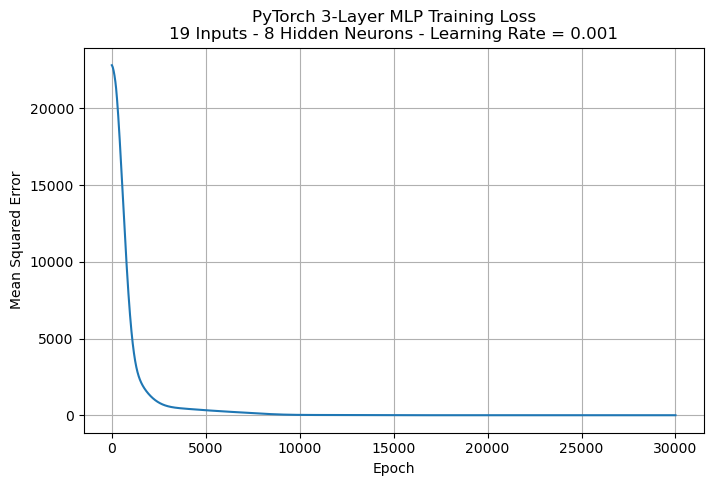

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(torch_loss1)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title(
    "PyTorch 3-Layer MLP Training Loss\n"
    "19 Inputs - 8 Hidden Neurons - Learning Rate = 0.001"
)

plt.grid(True)
plt.savefig(
    "pytorch_3layer_training_loss.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [36]:
# PyTorch Hidden-Neuron Comparison
# All sensing variables
# Learning rate = 0.001

hidden_sizes = [8, 16, 32]

torch_hidden_results = []

for hidden_size in hidden_sizes:

    torch.manual_seed(42)

    model, loss_history = train_torch_mlp(
        X_all_train_scaled,
        y_train,
        input_size=X_all_train_scaled.shape[1],
        hidden_size=hidden_size,
        learning_rate=0.001,
        epochs=30000
    )

    # Convert data to tensors
    X_train_tensor = torch.tensor(
        X_all_train_scaled,
        dtype=torch.float32
    )

    X_test_tensor = torch.tensor(
        X_all_test_scaled,
        dtype=torch.float32
    )

    # Predictions
    model.eval()

    with torch.no_grad():

        y_train_pred = model(
            X_train_tensor
        ).numpy().flatten()

        y_test_pred = model(
            X_test_tensor
        ).numpy().flatten()

    # Evaluation
    train_rmse, train_r2 = evaluate_regression(
        y_train,
        y_train_pred
    )

    test_rmse, test_r2 = evaluate_regression(
        y_test,
        y_test_pred
    )

    torch_hidden_results.append({
        "hidden_neurons": hidden_size,
        "train_rmse": train_rmse,
        "train_r2": train_r2,
        "test_rmse": test_rmse,
        "test_r2": test_r2,
        "final_loss": loss_history[-1]
    })

    print("Hidden neurons =", hidden_size)
    print("Train RMSE:", train_rmse)
    print("Train R2:", train_r2)
    print("Test RMSE:", test_rmse)
    print("Test R2:", test_r2)
    print("Final loss:", loss_history[-1])
    print("-" * 50)

Hidden neurons = 8
Train RMSE: 3.158235258672415
Train R2: 0.34524769610858674
Test RMSE: 3.3318639060581403
Test R2: 0.23181934652652803
Final loss: 9.97445011138916
--------------------------------------------------
Hidden neurons = 16
Train RMSE: 3.1582352870447346
Train R2: 0.34524768434452213
Test RMSE: 3.3318043232971277
Test R2: 0.2318468205868931
Final loss: 9.974454879760742
--------------------------------------------------
Hidden neurons = 32
Train RMSE: 3.104136037220028
Train R2: 0.3674868319887804
Test RMSE: 3.9799473500406495
Test R2: -0.09608317542510258
Final loss: 9.6356782913208
--------------------------------------------------


In [37]:
print("PYTORCH 3-LAYER MLP - HIDDEN NEURON COMPARISON")
print("=" * 75)

print(
    f"{'Hidden':<10}"
    f"{'Train RMSE':<15}"
    f"{'Train R2':<15}"
    f"{'Test RMSE':<15}"
    f"{'Test R2':<15}"
)

for result in torch_hidden_results:

    print(
        f"{result['hidden_neurons']:<10}"
        f"{result['train_rmse']:<15.4f}"
        f"{result['train_r2']:<15.4f}"
        f"{result['test_rmse']:<15.4f}"
        f"{result['test_r2']:<15.4f}"
    )

PYTORCH 3-LAYER MLP - HIDDEN NEURON COMPARISON
Hidden    Train RMSE     Train R2       Test RMSE      Test R2        
8         3.1582         0.3452         3.3319         0.2318         
16        3.1582         0.3452         3.3318         0.2318         
32        3.1041         0.3675         3.9799         -0.0961        


### Hidden-Neuron Comparison

The PyTorch three-layer MLP was evaluated using hidden-layer sizes of 8, 16,
and 32 neurons.

The models with 8 and 16 hidden neurons produced nearly identical performance,
with test RMSE values of approximately **3.3319** and **3.3318**, respectively,
and test R² values of approximately **0.2318**.

The 32-neuron model achieved better training performance but substantially worse
testing performance, with a test RMSE of approximately **3.9799** and a negative
test R² of approximately **-0.0961**.

This suggests that increasing the hidden-layer size to 32 neurons reduced
generalization performance. Therefore, **8 hidden neurons** were selected for
the learning-rate comparison.

In [38]:
# PyTorch Learning-Rate Comparison
# All sensing variables
# Hidden neurons = 8

learning_rates = [0.0005, 0.001, 0.005]

torch_lr_results = []

for lr in learning_rates:

    torch.manual_seed(42)

    model, loss_history = train_torch_mlp(
        X_all_train_scaled,
        y_train,
        input_size=X_all_train_scaled.shape[1],
        hidden_size=8,
        learning_rate=lr,
        epochs=30000
    )

    X_train_tensor = torch.tensor(
        X_all_train_scaled,
        dtype=torch.float32
    )

    X_test_tensor = torch.tensor(
        X_all_test_scaled,
        dtype=torch.float32
    )

    model.eval()

    with torch.no_grad():

        y_train_pred = model(
            X_train_tensor
        ).numpy().flatten()

        y_test_pred = model(
            X_test_tensor
        ).numpy().flatten()

    train_rmse, train_r2 = evaluate_regression(
        y_train,
        y_train_pred
    )

    test_rmse, test_r2 = evaluate_regression(
        y_test,
        y_test_pred
    )

    torch_lr_results.append({
        "learning_rate": lr,
        "train_rmse": train_rmse,
        "train_r2": train_r2,
        "test_rmse": test_rmse,
        "test_r2": test_r2,
        "final_loss": loss_history[-1]
    })

    print("Learning rate =", lr)
    print("Train RMSE:", train_rmse)
    print("Train R2:", train_r2)
    print("Test RMSE:", test_rmse)
    print("Test R2:", test_r2)
    print("Final loss:", loss_history[-1])
    print("-" * 50)

Learning rate = 0.0005
Train RMSE: 3.1582354776265094
Train R2: 0.3452476053232644
Test RMSE: 3.3318324113902036
Test R2: 0.2318338690166014
Final loss: 9.974451065063477
--------------------------------------------------
Learning rate = 0.001
Train RMSE: 3.158235258672415
Train R2: 0.34524769610858674
Test RMSE: 3.3318639060581403
Test R2: 0.23181934652652803
Final loss: 9.97445011138916
--------------------------------------------------
Learning rate = 0.005
Train RMSE: 3.1542886101990453
Train R2: 0.3468830794093879
Test RMSE: 3.4378165300497945
Test R2: 0.1821865503689205
Final loss: 9.949543952941895
--------------------------------------------------


In [39]:
print("PYTORCH 3-LAYER MLP - LEARNING RATE COMPARISON")
print("=" * 75)

print(
    f"{'Learning Rate':<18}"
    f"{'Train RMSE':<15}"
    f"{'Train R2':<15}"
    f"{'Test RMSE':<15}"
    f"{'Test R2':<15}"
)

for result in torch_lr_results:

    print(
        f"{result['learning_rate']:<18}"
        f"{result['train_rmse']:<15.4f}"
        f"{result['train_r2']:<15.4f}"
        f"{result['test_rmse']:<15.4f}"
        f"{result['test_r2']:<15.4f}"
    )

PYTORCH 3-LAYER MLP - LEARNING RATE COMPARISON
Learning Rate     Train RMSE     Train R2       Test RMSE      Test R2        
0.0005            3.1582         0.3452         3.3318         0.2318         
0.001             3.1582         0.3452         3.3319         0.2318         
0.005             3.1543         0.3469         3.4378         0.1822         


### Learning-Rate Comparison

Three learning rates were evaluated for the PyTorch three-layer MLP using
8 hidden neurons and all sensing variables.

The learning rates of **0.0005** and **0.001** produced nearly identical
performance, with test RMSE values of approximately **3.3318–3.3319**
and test R² values of approximately **0.2318**.

The larger learning rate of **0.005** produced slightly better training
performance but poorer test performance, with a test RMSE of approximately
**3.4378** and a test R² of approximately **0.1822**.

Therefore, a learning rate of **0.0005** was selected for the final
input-variable comparison.

In [40]:
# PyTorch Input Variable Comparison
# Hidden neurons = 8
# Learning rate = 0.0005

feature_sets_torch = {
    "All sensing variables x7-x25": (
        X_all_train_scaled,
        X_all_test_scaled
    ),
    "Pad and dresser variables x7-x10": (
        X_pad_train_scaled,
        X_pad_test_scaled
    )
}

torch_feature_results = []

for feature_name, (X_train_set, X_test_set) in feature_sets_torch.items():

    torch.manual_seed(42)

    model, loss_history = train_torch_mlp(
        X_train_set,
        y_train,
        input_size=X_train_set.shape[1],
        hidden_size=8,
        learning_rate=0.0005,
        epochs=30000
    )

    X_train_tensor = torch.tensor(
        X_train_set,
        dtype=torch.float32
    )

    X_test_tensor = torch.tensor(
        X_test_set,
        dtype=torch.float32
    )

    model.eval()

    with torch.no_grad():

        y_train_pred = model(
            X_train_tensor
        ).numpy().flatten()

        y_test_pred = model(
            X_test_tensor
        ).numpy().flatten()

    train_rmse, train_r2 = evaluate_regression(
        y_train,
        y_train_pred
    )

    test_rmse, test_r2 = evaluate_regression(
        y_test,
        y_test_pred
    )

    torch_feature_results.append({
        "feature_set": feature_name,
        "train_rmse": train_rmse,
        "train_r2": train_r2,
        "test_rmse": test_rmse,
        "test_r2": test_r2
    })

    print(feature_name)
    print("Train RMSE:", train_rmse)
    print("Train R2:", train_r2)
    print("Test RMSE:", test_rmse)
    print("Test R2:", test_r2)
    print("-" * 60)

All sensing variables x7-x25
Train RMSE: 3.1582354776265094
Train R2: 0.3452476053232644
Test RMSE: 3.3318324113902036
Test R2: 0.2318338690166014
------------------------------------------------------------
Pad and dresser variables x7-x10
Train RMSE: 3.3632109401076775
Train R2: 0.2575002804479384
Test RMSE: 3.2626515661685302
Test R2: 0.2634024847553681
------------------------------------------------------------


In [41]:
print("PYTORCH 3-LAYER MLP - INPUT VARIABLE COMPARISON")
print("=" * 85)

print(
    f"{'Feature Set':<38}"
    f"{'Train RMSE':<15}"
    f"{'Train R2':<15}"
    f"{'Test RMSE':<15}"
    f"{'Test R2':<15}"
)

for result in torch_feature_results:

    print(
        f"{result['feature_set']:<38}"
        f"{result['train_rmse']:<15.4f}"
        f"{result['train_r2']:<15.4f}"
        f"{result['test_rmse']:<15.4f}"
        f"{result['test_r2']:<15.4f}"
    )

PYTORCH 3-LAYER MLP - INPUT VARIABLE COMPARISON
Feature Set                           Train RMSE     Train R2       Test RMSE      Test R2        
All sensing variables x7-x25          3.1582         0.3452         3.3318         0.2318         
Pad and dresser variables x7-x10      3.3632         0.2575         3.2627         0.2634         


### Input-Variable Comparison

The PyTorch three-layer MLP was evaluated using both input-variable combinations.

Using all 19 sensing variables produced a test RMSE of approximately **3.3318**
and a test R² of approximately **0.2318**.

Using only the four pad and dresser condition variables (x7–x10) produced better
testing performance, with a test RMSE of approximately **3.2627** and a test
R² of approximately **0.2634**.

Although the model using all sensing variables achieved better training performance,
the reduced x7–x10 feature set generalized better to the test data.

This result suggests that the pad and dresser condition variables contain strong
predictive information for MRR, while some of the additional sensing variables may
not improve generalization in the PyTorch model.

## 9. Four-Layer MLP Using Self-Coded Forward and Backpropagation

The self-coded three-layer MLP is extended to a four-layer neural network by
introducing a second hidden layer.

The network architecture consists of:

1. Input layer
2. First hidden layer
3. Second hidden layer
4. Linear output layer for MRR prediction

ReLU activation is used in both hidden layers, while the output layer remains linear.

Forward propagation and backpropagation are implemented manually without using
PyTorch or Scikit-learn neural-network modules.

In [42]:
# Self-Coded Four-Layer MLP

class MLP4LayerScratch:

    def __init__(
        self,
        input_size,
        hidden_size1,
        hidden_size2,
        learning_rate=0.0005,
        random_state=42
    ):

        np.random.seed(random_state)

        self.learning_rate = learning_rate

        # Input - Hidden Layer 1
        self.W1 = np.random.randn(
            input_size,
            hidden_size1
        ) * np.sqrt(2.0 / input_size)

        self.b1 = np.zeros((1, hidden_size1))

        # Hidden Layer 1 - Hidden Layer 2
        self.W2 = np.random.randn(
            hidden_size1,
            hidden_size2
        ) * np.sqrt(2.0 / hidden_size1)

        self.b2 = np.zeros((1, hidden_size2))

        # Hidden Layer 2 - Output
        self.W3 = np.random.randn(
            hidden_size2,
            1
        ) * np.sqrt(2.0 / hidden_size2)

        self.b3 = np.zeros((1, 1))

        self.loss_history = []


    def relu(self, z):
        return np.maximum(0, z)


    def relu_derivative(self, z):
        return (z > 0).astype(float)



    # Forward propagation
  

    def forward(self, X):

        self.Z1 = np.dot(X, self.W1) + self.b1
        self.A1 = self.relu(self.Z1)

        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = self.relu(self.Z2)

        self.Z3 = np.dot(self.A2, self.W3) + self.b3

        return self.Z3


  
    # Backpropagation
  

    def backward(self, X, y, y_pred):

        n_samples = X.shape[0]

        y = y.reshape(-1, 1)

        # Output layer
        dZ3 = (2 / n_samples) * (y_pred - y)

        dW3 = np.dot(self.A2.T, dZ3)
        db3 = np.sum(dZ3, axis=0, keepdims=True)

        # Hidden layer 2
        dA2 = np.dot(dZ3, self.W3.T)

        dZ2 = dA2 * self.relu_derivative(self.Z2)

        dW2 = np.dot(self.A1.T, dZ2)
        db2 = np.sum(dZ2, axis=0, keepdims=True)

        # Hidden layer 1
        dA1 = np.dot(dZ2, self.W2.T)

        dZ1 = dA1 * self.relu_derivative(self.Z1)

        dW1 = np.dot(X.T, dZ1)
        db1 = np.sum(dZ1, axis=0, keepdims=True)

        # Update parameters
        self.W3 -= self.learning_rate * dW3
        self.b3 -= self.learning_rate * db3

        self.W2 -= self.learning_rate * dW2
        self.b2 -= self.learning_rate * db2

        self.W1 -= self.learning_rate * dW1
        self.b1 -= self.learning_rate * db1


  
    # Training
  

    def fit(self, X, y, epochs=10000):

        self.loss_history = []

        y_column = y.reshape(-1, 1)

        for epoch in range(epochs):

            y_pred = self.forward(X)

            loss = np.mean(
                (y_pred - y_column) ** 2
            )

            self.loss_history.append(loss)

            self.backward(
                X,
                y,
                y_pred
            )

        return self


    # Prediction
  

    def predict(self, X):

        return self.forward(X).flatten()

### 9.1 Initial Four-Layer MLP Trial

The first four-layer MLP experiment uses all 19 sensing variables with two hidden layers.

The network architecture is:

**19 inputs → 16 hidden neurons → 8 hidden neurons → 1 MRR output**

A learning rate of **0.0005** is used, and the network is trained for 10,000 epochs.

The purpose of this trial is to evaluate whether adding a second hidden layer improves
MRR prediction compared with the three-layer MLP.

In [43]:
# Self-Coded 4-Layer MLP - Trial 1
# All sensing variables
# Architecture: 19 - 16 - 8 - 1
# Learning rate = 0.0005

mlp4_trial1 = MLP4LayerScratch(
    input_size=X_all_train_scaled.shape[1],
    hidden_size1=16,
    hidden_size2=8,
    learning_rate=0.0005,
    random_state=42
)

mlp4_trial1.fit(
    X_all_train_scaled,
    y_train,
    epochs=10000
)

# Predictions
y_train_pred_mlp4_1 = mlp4_trial1.predict(
    X_all_train_scaled
)

y_test_pred_mlp4_1 = mlp4_trial1.predict(
    X_all_test_scaled
)

# Evaluation
train_rmse_mlp4_1, train_r2_mlp4_1 = evaluate_regression(
    y_train,
    y_train_pred_mlp4_1
)

test_rmse_mlp4_1, test_r2_mlp4_1 = evaluate_regression(
    y_test,
    y_test_pred_mlp4_1
)

print("SELF-CODED 4-LAYER MLP - TRIAL 1")
print("=" * 55)

print("Architecture: 19 -> 16 -> 8 -> 1")
print("Learning rate: 0.0005")
print("Epochs: 10000")

print("\nTraining Performance")
print("RMSE:", train_rmse_mlp4_1)
print("R2:", train_r2_mlp4_1)

print("\nTesting Performance")
print("RMSE:", test_rmse_mlp4_1)
print("R2:", test_r2_mlp4_1)

print("\nInitial loss:", mlp4_trial1.loss_history[0])
print("Final loss:", mlp4_trial1.loss_history[-1])

SELF-CODED 4-LAYER MLP - TRIAL 1
Architecture: 19 -> 16 -> 8 -> 1
Learning rate: 0.0005
Epochs: 10000

Training Performance
RMSE: 2.7417876525804448
R2: 0.5065357300048796

Testing Performance
RMSE: 3.458647840540002
R2: 0.1722455074996777

Initial loss: 22679.50705786593
Final loss: 7.489853614179848


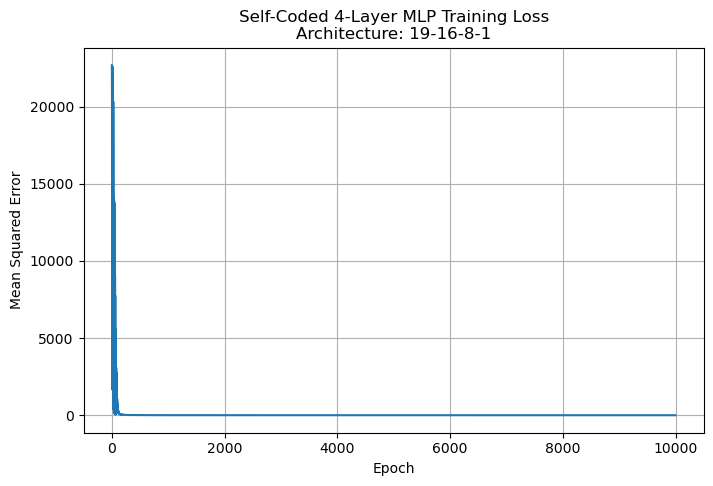

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(mlp4_trial1.loss_history)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title(
    "Self-Coded 4-Layer MLP Training Loss\n"
    "Architecture: 19-16-8-1"
)

plt.grid(True)
plt.savefig(
    "self_coded_4layer_mlp_loss.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [45]:
# Self-Coded 4-Layer MLP Architecture Comparison
# All sensing variables
# Learning rate = 0.0005

architectures = [
    (16, 8),
    (32, 16),
    (8, 4)
]

mlp4_arch_results = []

for hidden1, hidden2 in architectures:

    model = MLP4LayerScratch(
        input_size=X_all_train_scaled.shape[1],
        hidden_size1=hidden1,
        hidden_size2=hidden2,
        learning_rate=0.0005,
        random_state=42
    )

    model.fit(
        X_all_train_scaled,
        y_train,
        epochs=10000
    )

    # Predictions
    y_train_pred = model.predict(
        X_all_train_scaled
    )

    y_test_pred = model.predict(
        X_all_test_scaled
    )

    # Evaluation
    train_rmse, train_r2 = evaluate_regression(
        y_train,
        y_train_pred
    )

    test_rmse, test_r2 = evaluate_regression(
        y_test,
        y_test_pred
    )

    mlp4_arch_results.append({
        "architecture": f"19-{hidden1}-{hidden2}-1",
        "train_rmse": train_rmse,
        "train_r2": train_r2,
        "test_rmse": test_rmse,
        "test_r2": test_r2,
        "final_loss": model.loss_history[-1]
    })

    print(f"Architecture: 19 -> {hidden1} -> {hidden2} -> 1")
    print("Train RMSE:", train_rmse)
    print("Train R2:", train_r2)
    print("Test RMSE:", test_rmse)
    print("Test R2:", test_r2)
    print("Final loss:", model.loss_history[-1])
    print("-" * 60)

Architecture: 19 -> 16 -> 8 -> 1
Train RMSE: 2.7417876525804448
Train R2: 0.5065357300048796
Test RMSE: 3.458647840540002
Test R2: 0.1722455074996777
Final loss: 7.489853614179848
------------------------------------------------------------
Architecture: 19 -> 32 -> 16 -> 1
Train RMSE: 2.7674990539041078
Train R2: 0.49723730910484654
Test RMSE: 3.615163372081169
Test R2: 0.09563298476672977
Final loss: 7.674065285599403
------------------------------------------------------------
Architecture: 19 -> 8 -> 4 -> 1
Train RMSE: 2.840142069663061
Train R2: 0.4704972626543942
Test RMSE: 3.417584303362137
Test R2: 0.19178421107805255
Final loss: 8.070992290051883
------------------------------------------------------------


In [46]:
print("SELF-CODED 4-LAYER MLP - ARCHITECTURE COMPARISON")
print("=" * 80)

print(
    f"{'Architecture':<20}"
    f"{'Train RMSE':<15}"
    f"{'Train R2':<15}"
    f"{'Test RMSE':<15}"
    f"{'Test R2':<15}"
)

for result in mlp4_arch_results:

    print(
        f"{result['architecture']:<20}"
        f"{result['train_rmse']:<15.4f}"
        f"{result['train_r2']:<15.4f}"
        f"{result['test_rmse']:<15.4f}"
        f"{result['test_r2']:<15.4f}"
    )

SELF-CODED 4-LAYER MLP - ARCHITECTURE COMPARISON
Architecture        Train RMSE     Train R2       Test RMSE      Test R2        
19-16-8-1           2.7418         0.5065         3.4586         0.1722         
19-32-16-1          2.7675         0.4972         3.6152         0.0956         
19-8-4-1            2.8401         0.4705         3.4176         0.1918         


### Four-Layer Architecture Comparison

Three four-layer MLP architectures were evaluated using all 19 sensing variables.

The **19–8–4–1** architecture produced the best testing performance, with a
test RMSE of approximately **3.4176** and a test R² of approximately **0.1918**.

The larger architectures achieved lower training errors but poorer testing
performance. This indicates that increasing network complexity improved the fit
to the training data but reduced generalization.

Therefore, the **19–8–4–1** architecture was selected for the remaining
four-layer MLP experiments.

In [47]:
# Self-Coded 4-Layer MLP - Learning Rate Comparison
# Architecture: 19 - 8 - 4 - 1

learning_rates_4layer = [0.0002, 0.0005, 0.001]

mlp4_lr_results = []

for lr in learning_rates_4layer:

    model = MLP4LayerScratch(
        input_size=X_all_train_scaled.shape[1],
        hidden_size1=8,
        hidden_size2=4,
        learning_rate=lr,
        random_state=42
    )

    model.fit(
        X_all_train_scaled,
        y_train,
        epochs=10000
    )

    # Predictions
    y_train_pred = model.predict(
        X_all_train_scaled
    )

    y_test_pred = model.predict(
        X_all_test_scaled
    )

    # Evaluation
    train_rmse, train_r2 = evaluate_regression(
        y_train,
        y_train_pred
    )

    test_rmse, test_r2 = evaluate_regression(
        y_test,
        y_test_pred
    )

    mlp4_lr_results.append({
        "learning_rate": lr,
        "train_rmse": train_rmse,
        "train_r2": train_r2,
        "test_rmse": test_rmse,
        "test_r2": test_r2
    })

    print("Learning rate =", lr)
    print("Train RMSE:", train_rmse)
    print("Train R2:", train_r2)
    print("Test RMSE:", test_rmse)
    print("Test R2:", test_r2)
    print("-" * 50)

Learning rate = 0.0002
Train RMSE: 2.9231504289366494
Train R2: 0.43909358064681925
Test RMSE: 3.2684559054979583
Test R2: 0.2607793024031333
--------------------------------------------------
Learning rate = 0.0005
Train RMSE: 2.840142069663061
Train R2: 0.4704972626543942
Test RMSE: 3.417584303362137
Test R2: 0.19178421107805255
--------------------------------------------------
Learning rate = 0.001
Train RMSE: 3.9030665833658467
Train R2: -6.439293542825908e-15
Test RMSE: 3.819739563915302
Test R2: -0.009616323641423286
--------------------------------------------------


In [48]:
print("SELF-CODED 4-LAYER MLP - LEARNING RATE COMPARISON")
print("=" * 75)

print(
    f"{'Learning Rate':<18}"
    f"{'Train RMSE':<15}"
    f"{'Train R2':<15}"
    f"{'Test RMSE':<15}"
    f"{'Test R2':<15}"
)

for result in mlp4_lr_results:

    print(
        f"{result['learning_rate']:<18}"
        f"{result['train_rmse']:<15.4f}"
        f"{result['train_r2']:<15.4f}"
        f"{result['test_rmse']:<15.4f}"
        f"{result['test_r2']:<15.4f}"
    )

SELF-CODED 4-LAYER MLP - LEARNING RATE COMPARISON
Learning Rate     Train RMSE     Train R2       Test RMSE      Test R2        
0.0002            2.9232         0.4391         3.2685         0.2608         
0.0005            2.8401         0.4705         3.4176         0.1918         
0.001             3.9031         -0.0000        3.8197         -0.0096        


### Four-Layer Learning-Rate Comparison

Three learning rates were evaluated for the 19–8–4–1 four-layer MLP architecture.

The learning rate of **0.0002** produced the best testing performance, with a
test RMSE of approximately **3.2685** and a test R² of approximately **0.2608**.

The learning rate of **0.0005** achieved better training performance but poorer
testing performance, indicating reduced generalization.

The larger learning rate of **0.001** produced very poor performance, with a
negative test R², showing that the learning rate was too large for this
four-layer network.

Therefore, **0.0002** was selected for the final input-variable comparison.

In [49]:
# Self-Coded 4-Layer MLP - Input Variable Comparison
# Architecture: 8 - 4
# Learning rate = 0.0002

feature_sets_4layer = {
    "All sensing variables x7-x25": (
        X_all_train_scaled,
        X_all_test_scaled
    ),
    "Pad and dresser variables x7-x10": (
        X_pad_train_scaled,
        X_pad_test_scaled
    )
}

mlp4_feature_results = []

for feature_name, (X_train_set, X_test_set) in feature_sets_4layer.items():

    model = MLP4LayerScratch(
        input_size=X_train_set.shape[1],
        hidden_size1=8,
        hidden_size2=4,
        learning_rate=0.0002,
        random_state=42
    )

    model.fit(
        X_train_set,
        y_train,
        epochs=10000
    )

    y_train_pred = model.predict(X_train_set)
    y_test_pred = model.predict(X_test_set)

    train_rmse, train_r2 = evaluate_regression(
        y_train,
        y_train_pred
    )

    test_rmse, test_r2 = evaluate_regression(
        y_test,
        y_test_pred
    )

    mlp4_feature_results.append({
        "feature_set": feature_name,
        "train_rmse": train_rmse,
        "train_r2": train_r2,
        "test_rmse": test_rmse,
        "test_r2": test_r2
    })

    print(feature_name)
    print("Train RMSE:", train_rmse)
    print("Train R2:", train_r2)
    print("Test RMSE:", test_rmse)
    print("Test R2:", test_r2)
    print("-" * 60)

All sensing variables x7-x25
Train RMSE: 2.9231504289366494
Train R2: 0.43909358064681925
Test RMSE: 3.2684559054979583
Test R2: 0.2607793024031333
------------------------------------------------------------
Pad and dresser variables x7-x10
Train RMSE: 3.2408794690713054
Train R2: 0.3105324370011201
Test RMSE: 3.116032698474387
Test R2: 0.3281182103184006
------------------------------------------------------------


In [50]:
print("SELF-CODED 4-LAYER MLP - INPUT VARIABLE COMPARISON")
print("=" * 85)

print(
    f"{'Feature Set':<38}"
    f"{'Train RMSE':<15}"
    f"{'Train R2':<15}"
    f"{'Test RMSE':<15}"
    f"{'Test R2':<15}"
)

for result in mlp4_feature_results:

    print(
        f"{result['feature_set']:<38}"
        f"{result['train_rmse']:<15.4f}"
        f"{result['train_r2']:<15.4f}"
        f"{result['test_rmse']:<15.4f}"
        f"{result['test_r2']:<15.4f}"
    )

SELF-CODED 4-LAYER MLP - INPUT VARIABLE COMPARISON
Feature Set                           Train RMSE     Train R2       Test RMSE      Test R2        
All sensing variables x7-x25          2.9232         0.4391         3.2685         0.2608         
Pad and dresser variables x7-x10      3.2409         0.3105         3.1160         0.3281         


### Four-Layer Input-Variable Comparison

The final four-layer MLP was evaluated using both input-variable combinations.

Using all 19 sensing variables produced a test RMSE of approximately **3.2685**
and a test R² of approximately **0.2608**.

Using only the four pad and dresser condition variables (x7–x10) produced
substantially better testing performance, with a test RMSE of approximately
**3.1160** and a test R² of approximately **0.3281**.

Although the model using all 19 variables achieved better training performance,
the reduced x7–x10 model generalized better to unseen data.

This result further supports the importance of the polishing pad and dresser
condition variables in predicting MRR and shows that increasing the number of
input variables does not necessarily improve prediction accuracy.

In [51]:
# Final Overall Model Comparison

final_results = [
    {
        "Model": "Gradient Descent Regression",
        "Features": "All x7-x25",
        "Test RMSE": 3.2349,
        "Test R2": 0.2759
    },
    {
        "Model": "Sklearn Linear Regression",
        "Features": "x7-x10",
        "Test RMSE": 3.2627,
        "Test R2": 0.2634
    },
    {
        "Model": "Self-Coded 3-Layer MLP",
        "Features": "All x7-x25",
        "Test RMSE": 3.2383,
        "Test R2": 0.2743
    },
    {
        "Model": "PyTorch 3-Layer MLP",
        "Features": "x7-x10",
        "Test RMSE": 3.2627,
        "Test R2": 0.2634
    },
    {
        "Model": "Self-Coded 4-Layer MLP",
        "Features": "x7-x10",
        "Test RMSE": 3.1160,
        "Test R2": 0.3281
    }
]

print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 85)

print(
    f"{'Model':<32}"
    f"{'Features':<18}"
    f"{'Test RMSE':<15}"
    f"{'Test R2':<15}"
)

for result in final_results:

    print(
        f"{result['Model']:<32}"
        f"{result['Features']:<18}"
        f"{result['Test RMSE']:<15.4f}"
        f"{result['Test R2']:<15.4f}"
    )
   

FINAL MODEL PERFORMANCE COMPARISON
Model                           Features          Test RMSE      Test R2        
Gradient Descent Regression     All x7-x25        3.2349         0.2759         
Sklearn Linear Regression       x7-x10            3.2627         0.2634         
Self-Coded 3-Layer MLP          All x7-x25        3.2383         0.2743         
PyTorch 3-Layer MLP             x7-x10            3.2627         0.2634         
Self-Coded 4-Layer MLP          x7-x10            3.1160         0.3281         


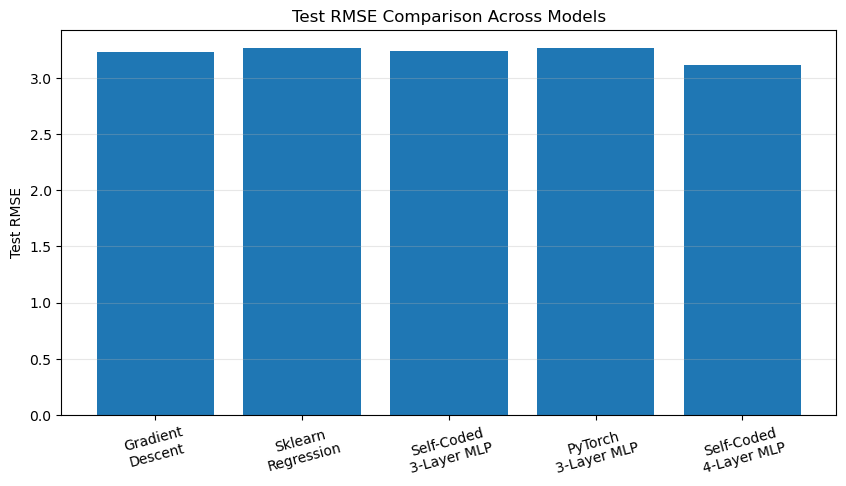

In [52]:
# Final RMSE Comparison Plot

model_names = [
    "Gradient\nDescent",
    "Sklearn\nRegression",
    "Self-Coded\n3-Layer MLP",
    "PyTorch\n3-Layer MLP",
    "Self-Coded\n4-Layer MLP"
]

rmse_values = [
    3.2349,
    3.2627,
    3.2383,
    3.2627,
    3.1160
]

plt.figure(figsize=(10, 5))

plt.bar(model_names, rmse_values)

plt.ylabel("Test RMSE")
plt.title("Test RMSE Comparison Across Models")

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

# Save BEFORE show
plt.savefig(
    "final_model_rmse_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

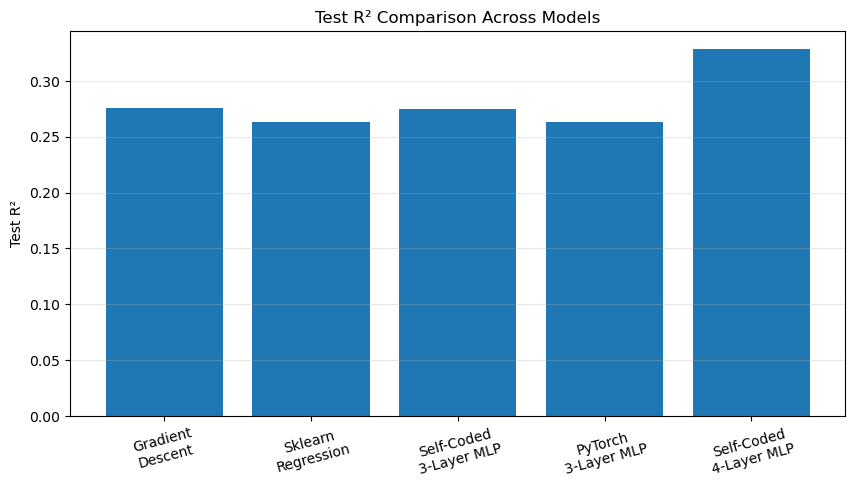

In [53]:
# Final R2 Comparison Plot

r2_values = [
    0.2759,
    0.2634,
    0.2743,
    0.2634,
    0.3281
]

plt.figure(figsize=(10, 5))

plt.bar(model_names, r2_values)

plt.ylabel("Test R²")
plt.title("Test R² Comparison Across Models")

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

# Save BEFORE show
plt.savefig(
    "final_model_r2_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

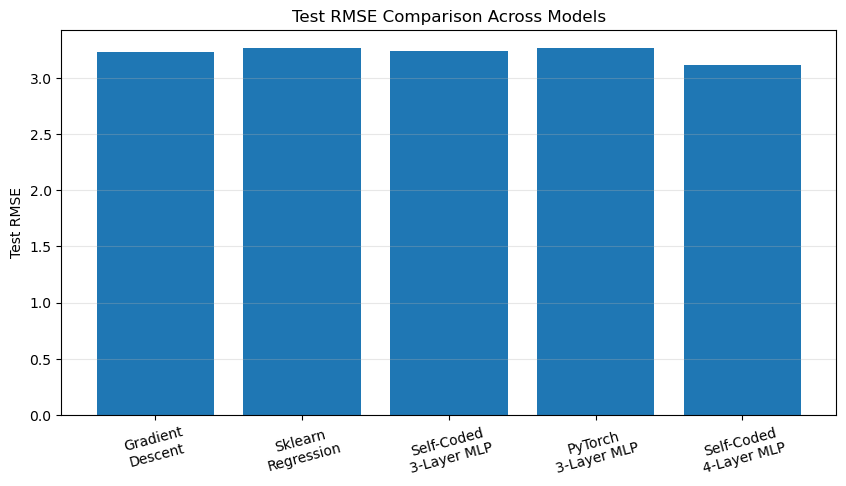

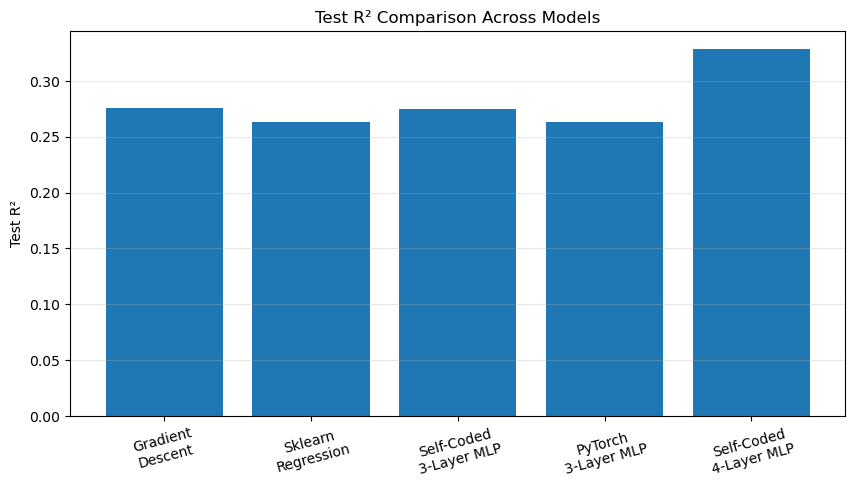

In [54]:
# Final Model Performance Visualization

model_names = [
    "Gradient\nDescent",
    "Sklearn\nRegression",
    "Self-Coded\n3-Layer MLP",
    "PyTorch\n3-Layer MLP",
    "Self-Coded\n4-Layer MLP"
]

rmse_values = [
    3.2349,
    3.2627,
    3.2383,
    3.2627,
    3.1160
]

r2_values = [
    0.2759,
    0.2634,
    0.2743,
    0.2634,
    0.3281
]

# RMSE comparison

plt.figure(figsize=(10, 5))

plt.bar(model_names, rmse_values)

plt.ylabel("Test RMSE")
plt.title("Test RMSE Comparison Across Models")

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.show()

# R2 comparison
plt.figure(figsize=(10, 5))

plt.bar(model_names, r2_values)

plt.ylabel("Test R²")
plt.title("Test R² Comparison Across Models")

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.show()

## 10. Overall Model Performance and Discussion

The five modeling approaches were compared using Root Mean Square Error (RMSE)
and the coefficient of determination (R²) on the same test dataset.

Among all evaluated models, the **self-coded four-layer MLP using the pad and
dresser condition variables x7–x10 achieved the best overall performance**.
It produced a test RMSE of approximately **3.1160** and a test R² of
approximately **0.3281**.

The gradient-descent multiple regression model using all 19 sensing variables
also performed competitively, with a test RMSE of approximately **3.2349**
and a test R² of approximately **0.2759**.

The best self-coded three-layer MLP produced a similar result, with a test RMSE
of approximately **3.2383** and a test R² of approximately **0.2743**.

An important observation across the experiments is that using more sensing
variables did not always improve test performance. In particular, the
four-layer MLP performed substantially better using only x7–x10 than when using
all 19 sensing variables.

This finding suggests that the condition of the polishing pad and dresser
contains important predictive information for MRR. The additional sensing
variables may provide useful process information, but they do not necessarily
improve generalization for every model.

The experiments also showed that increased neural-network complexity does not
automatically produce better results. Larger hidden layers generally improved
training performance but sometimes reduced test performance, indicating
overfitting.

Overall, both feature selection and model complexity had important effects on
MRR prediction performance.

## 11. Difficulties and Lessons Learned

Several practical lessons were learned during the implementation of the models.

### Learning Rate Selection

The learning rate had a strong effect on model training. Very small learning
rates produced slow convergence, while excessively large learning rates reduced
model performance or resulted in unstable optimization. This demonstrated the
importance of selecting a learning rate appropriate for the model architecture.

### Model Convergence

The gradient-descent experiments showed that convergence should not be judged
only from the number of iterations. The loss curve is also important for
determining whether the optimization process has stabilized.

### Feature Selection

Using all available sensing variables did not always produce the best testing
performance. In several experiments, the reduced x7–x10 feature set performed
similarly to or better than the full 19-variable input set.

This demonstrated that more input variables do not automatically lead to a
better predictive model.

### Neural-Network Complexity

Increasing the number of hidden neurons improved training performance but often
reduced testing performance. This illustrated the difference between fitting
the training data and generalizing to unseen observations.

### Manual Backpropagation

Implementing the forward and backward propagation algorithms manually improved
understanding of how gradients are calculated and how neural-network weights
and biases are updated.

### PyTorch Implementation

The PyTorch implementation simplified gradient calculation because
backpropagation was handled automatically. Comparing the self-coded MLP with
PyTorch helped illustrate the difference between manually implementing the
learning algorithm and using an established deep-learning library.

### Data Preprocessing

Normalization was particularly important for gradient-based methods because the
sensing variables originally had very different numerical ranges. Scaling the
inputs made optimization more stable and allowed the learning rates to have a
more consistent effect across variables.

## 12. Conclusion

This project investigated the prediction of Material Removal Rate (MRR) in a
Chemical Mechanical Polishing process using multiple regression and multilayer
perceptron models.

Two input-variable combinations were evaluated: all 19 sensing variables
(x7–x25) and the four polishing pad and dresser condition variables (x7–x10).

Multiple linear regression was implemented using both self-coded gradient
descent and Scikit-learn. Three-layer MLP models were also developed using
manual forward and backpropagation as well as the PyTorch `torch.nn` module.
Finally, the self-coded neural network was extended to a four-layer MLP.

Different learning rates, hidden-layer sizes, network architectures, and
feature combinations were evaluated using RMSE and R².

The best overall result was obtained using the **self-coded four-layer MLP with
the x7–x10 input variables**, which achieved a test RMSE of approximately
**3.1160** and a test R² of approximately **0.3281**.

The results demonstrate that increasing model complexity or adding more input
variables does not necessarily improve prediction accuracy. Feature selection,
learning rate, network size, and generalization performance must all be
considered when developing machine-learning models for MRR prediction.

The strong performance of the x7–x10 input combination also supports the
importance of polishing pad and dresser condition in determining Material
Removal Rate.